# Лабораторная работа №2 — CNN для CIFAR-10

**Цель:** реализовать и обучить сверточную нейронную сеть в PyTorch. Все слои сети объявлены вручную; готовые модели не используются.


In [1]:
import time
import os

import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Устройство:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    torch.backends.cudnn.benchmark = True

Устройство: cuda
GPU: Tesla T4


## 1. Загрузка и предобработка CIFAR-10

В CIFAR-10: 50 000 обучающих и 10 000 тестовых цветных изображений размером **32 × 32 × 3**. Для обучения используются случайные отражения и сдвиги, тестовые данные не искажаются.

In [2]:
BATCH_SIZE = 128
EPOCHS = 25
LEARNING_RATE = 0.003

mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])


In [4]:
import os
from google.colab import drive
from torchvision import datasets

drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/Colab Notebooks/DL/data'

# Проверим, что папка существует
print("Папка DL есть:", os.path.isdir(PROJECT_DIR))

os.chdir(PROJECT_DIR)
print("cwd:", os.getcwd())

# ./files теперь ведёт в /content/drive/MyDrive/DL/files
os.makedirs('./files', exist_ok=True)

train_data = datasets.CIFAR10('./files', train=True, download=True, transform=train_transform)
test_data = datasets.CIFAR10('./files', train=False, download=True, transform=test_transform)

Mounted at /content/drive
Папка DL есть: True
cwd: /content/drive/MyDrive/Colab Notebooks/DL/data


In [5]:
workers = 0 if os.name == "nt" else 2
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=workers, pin_memory=(DEVICE == "cuda"))
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=workers, pin_memory=(DEVICE == "cuda"))

images, labels = next(iter(train_loader))
print("Train:", len(train_data), "Test:", len(test_data))
print("Форма изображения:", images[0].shape)
print("Форма меток в пачке:", labels.shape)
print("Метки:", train_data.classes)

Train: 50000 Test: 10000
Форма изображения: torch.Size([3, 32, 32])
Форма меток в пачке: torch.Size([128])
Метки: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


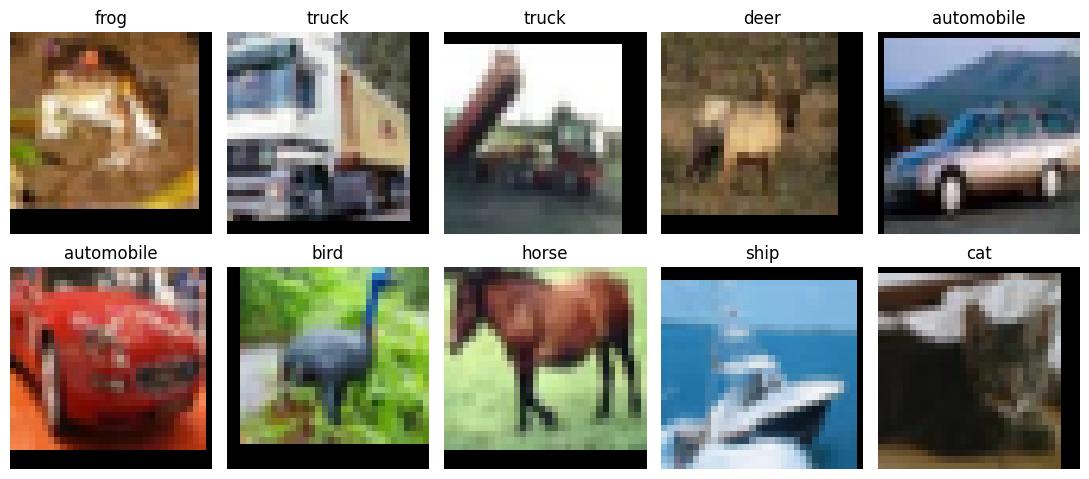

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for i, ax in enumerate(axes.flat):
    image, label = train_data[i]
    image = image.permute(1, 2, 0) * torch.tensor(std) + torch.tensor(mean)
    ax.imshow(image.clamp(0, 1))
    ax.set_title(train_data.classes[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Архитектура CNN — ResNet9

Сначала свёртки извлекают признаки, затем два остаточных блока добавляют преобразованные признаки к исходным: **выход = x + F(x)**. Это помогает распространению градиентов. В конце глобальное усреднение и линейный слой предсказывают 10 классов.

In [7]:
def conv_block(in_channels, out_channels, pool=False):
    layers = [
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True)
    ]
    if pool:
        layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers)


class ResNet9(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = conv_block(3, 64)
        self.conv2 = conv_block(64, 128, pool=True)
        self.res1 = nn.Sequential(conv_block(128, 128), conv_block(128, 128))
        self.conv3 = conv_block(128, 256, pool=True)
        self.conv4 = conv_block(256, 512, pool=True)
        self.res2 = nn.Sequential(conv_block(512, 512), conv_block(512, 512))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(512, 10)

    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = x + self.res1(x)
        x = self.conv3(x)
        x = self.conv4(x)
        x = x + self.res2(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)


model = ResNet9().to(DEVICE)
print("Количество параметров:", sum(p.numel() for p in model.parameters()))

Количество параметров: 6573130


## 3. Обучение

**Функция потерь:** `CrossEntropyLoss` (принимает логиты, `Softmax` добавлять не надо). **Оптимизатор:** AdamW. **План скорости обучения:** OneCycleLR. Для улучшения точности используем аугментации и регуляризацию весов. После каждой эпохи вычисляем точность и ошибку классификации **на всех 50 000 исходных обучающих изображениях** без аугментаций.

In [8]:
train_eval_data = datasets.CIFAR10("/content/drive/MyDrive/Colab Notebooks/DL/data/files", train=True, download=False, transform=test_transform)
train_eval_loader = DataLoader(train_eval_data, batch_size=BATCH_SIZE, shuffle=False,
                               num_workers=workers, pin_memory=(DEVICE == "cuda"))

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=LEARNING_RATE, epochs=EPOCHS, steps_per_epoch=len(train_loader)
)


def evaluate(loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(DEVICE), y.to(DEVICE)
            predicted = model(X).argmax(dim=1)
            correct += (predicted == y).sum().item()
            total += len(y)
    accuracy = 100 * correct / total
    return accuracy, 100 - accuracy

In [9]:
train_errors = []

for epoch in range(1, EPOCHS + 1):
    start = time.perf_counter()
    model.train()

    for X, y in train_loader:
        X, y = X.to(DEVICE), y.to(DEVICE)

        optimizer.zero_grad()
        loss = loss_fn(model(X), y)
        loss.backward()
        optimizer.step()
        scheduler.step()

    accuracy, error = evaluate(train_eval_loader)
    train_errors.append(error)
    elapsed = time.perf_counter() - start
    print(f"Эпоха {epoch}: ошибка {error}%, точность {accuracy}%, время {elapsed} с")

Эпоха 1: ошибка 39.454%, точность 60.546%, время 41.87607335399997 с
Эпоха 2: ошибка 36.828%, точность 63.172%, время 34.935683299999994 с
Эпоха 3: ошибка 27.134%, точность 72.866%, время 36.351778825999986 с
Эпоха 4: ошибка 29.664%, точность 70.336%, время 36.625131318 с
Эпоха 5: ошибка 23.141999999999996%, точность 76.858%, время 36.407349608000004 с
Эпоха 6: ошибка 16.680000000000007%, точность 83.32%, время 36.997894152000015 с
Эпоха 7: ошибка 15.200000000000003%, точность 84.8%, время 36.32065597400003 с
Эпоха 8: ошибка 16.361999999999995%, точность 83.638%, время 37.19597343099997 с
Эпоха 9: ошибка 10.781999999999996%, точность 89.218%, время 36.02318905000004 с
Эпоха 10: ошибка 12.560000000000002%, точность 87.44%, время 36.94725475500002 с
Эпоха 11: ошибка 8.831999999999994%, точность 91.168%, время 35.928328572000055 с
Эпоха 12: ошибка 11.123999999999995%, точность 88.876%, время 37.236231134000036 с
Эпоха 13: ошибка 8.754000000000005%, точность 91.246%, время 35.8427104879999

## 4. Тестирование и график

In [1]:
test_accuracy, test_error = evaluate(test_loader)
print("Тестовая ошибка:", test_error, "%")
print("Тестовая точность:", test_accuracy, "%")

NameError: name 'evaluate' is not defined

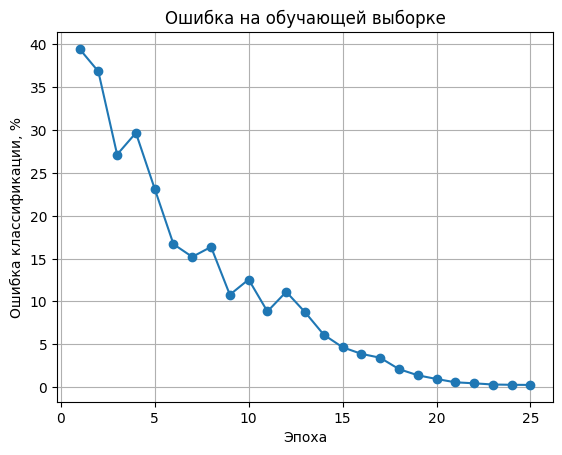

In [11]:
plt.plot(range(1, len(train_errors) + 1), train_errors, marker="o")
plt.xlabel("Эпоха")
plt.ylabel("Ошибка классификации, %")
plt.title("Ошибка на обучающей выборке")
plt.grid()
plt.show()

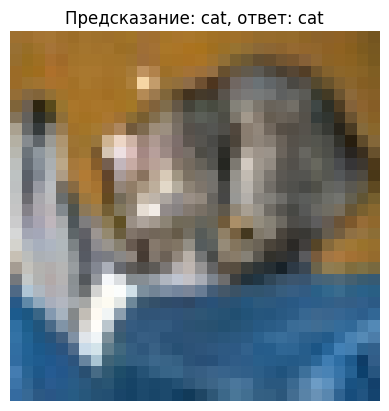

In [12]:
image, label = test_data[0]
model.eval()
with torch.no_grad():
    prediction = model(image.unsqueeze(0).to(DEVICE)).argmax(dim=1).item()

plt.imshow((image.permute(1, 2, 0) * torch.tensor(std) + torch.tensor(mean)).clamp(0, 1))
plt.title(f"Предсказание: {test_data.classes[prediction]}, ответ: {test_data.classes[label]}")
plt.axis("off")
plt.show()

## Вывод

В работе разработана и обучена CNN с остаточными соединениями на CIFAR-10. Итоговая точность ЗНАЧЕНИЕ.(добавлю значение чуть позже)